# Deep Learning Assignment 3
## Optimization, Regularization & Activation Functions

**Name:** Harry Lyu

**Student ID:** hl4067

**Course:** COMSW4726 Deep Learning for Data Science

In [8]:
import torch
from torch import nn, optim
from torch.utils.data import DataLoader, TensorDataset, random_split
from torchvision import datasets
import matplotlib.pyplot as plt

# Reproducibility
SEED = 42
torch.manual_seed(SEED)
torch.set_num_threads(2)

# Experiment settings
EPOCHS = 20
BATCH_SIZE = 256

## Load MNIST and split it into training and validation sets, create a new code cell

In [11]:
from pathlib import Path
DATA_DIR = Path.home() / "Documents" / "MNIST_data"

mnist = datasets.MNIST( root=str(DATA_DIR), train=True, download=True)
images = mnist.data.reshape(-1, 784).float() / 255.0
labels = mnist.targets

dataset = TensorDataset(images, labels)

train_set, val_set = random_split(dataset, [50000, 10000], generator=torch.Generator().manual_seed(SEED))

train_eval_loader = DataLoader(train_set, batch_size=1024, shuffle=False)
val_loader = DataLoader(val_set, batch_size=1024, shuffle=False)

print(f"Training samples: {len(train_set)}")
print(f"Validation samples: {len(val_set)}")
print(f"Input features: {images.shape[1]}")

Training samples: 50000
Validation samples: 10000
Input features: 784


## Define the neural network

In [13]:
def build_model(activation="ReLU", dropout=0.0):
    activations = {"ReLU": nn.ReLU(), "Sigmoid": nn.Sigmoid(), "Tanh": nn.Tanh()}

    model = nn.Sequential(nn.Linear(784, 128), activations[activation],
                          nn.Dropout(p=dropout), nn.Linear(128, 10))
    return model

criterion = nn.CrossEntropyLoss()

torch.manual_seed(SEED)
model = build_model()
print(model)

Sequential(
  (0): Linear(in_features=784, out_features=128, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.0, inplace=False)
  (3): Linear(in_features=128, out_features=10, bias=True)
)


## Define the evaluation function.

In [ ]:
def evaluate(model, loader):
    model.eval()

    total_loss = 0.0
    correct = 0
    total_samples = 0

    with torch.no_grad():
        for images, labels in loader:
            logits = model(images)
            loss = criterion(logits, labels)
            total_loss += loss.item() * labels.size(0)
            predictions = logits.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total_samples += labels.size(0)

    average_loss = total_loss / total_samples
    accuracy = correct / total_samples

    return average_loss, accuracy

## Define the training function.

In [19]:
def train_model(optimizer_name="Adam", regularization="None", activation="ReLU"):

    torch.manual_seed(SEED)
    dropout = 0.3 if regularization == "Dropout" else 0.0
    model = build_model(activation, dropout)

    # Set the optimizer and batch size
    batch_size = BATCH_SIZE

    if optimizer_name == "Adam":
        optimizer = optim.Adam(model.parameters(), lr=0.001)
    else:
        settings = {"Batch GD": (len(train_set), 0.2, 0.0), "SGD": (1, 0.01, 0.0),
            "Momentum": (BATCH_SIZE, 0.05, 0.9)}
        batch_size, lr, momentum = settings[optimizer_name]
        optimizer = optim.SGD(model.parameters(), lr=lr, momentum=momentum)

    loader = DataLoader(train_set, batch_size=batch_size, shuffle=True, 
                        generator=torch.Generator().manual_seed(SEED))

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    # Select weights, excluding biases
    weights = [p for p in model.parameters() if p.ndim > 1]

    for epoch in range(EPOCHS):
        model.train()

        for x, y in loader:
            optimizer.zero_grad()
            loss = criterion(model(x), y)

            if regularization == "L1":
                loss += 1e-5 * sum(w.abs().sum() for w in weights)
            elif regularization == "L2":
                loss += 0.5 * 1e-4 * sum(w.square().sum() for w in weights)

            loss.backward()
            optimizer.step()

        train_loss, train_acc = evaluate(model, train_eval_loader)
        val_loss, val_acc = evaluate(model, val_loader)
        values = [train_loss, val_loss, train_acc, val_acc]
        for key, value in zip(history, values):
            history[key].append(value)

        print(
            f"{optimizer_name} | {regularization} | {activation} | "
            f"Epoch {epoch + 1}/{EPOCHS} | "
            f"Train loss: {train_loss:.4f} | Val loss: {val_loss:.4f} | "
            f"Train acc: {train_acc:.2%} | Val acc: {val_acc:.2%}")

    weights = torch.cat([w.detach().flatten() for w in weights])
    history["weight_norm"] = weights.norm().item()
    history["near_zero_pct"] = (100 * (weights.abs() < 0.001).float().mean().item())

    return history

## Train four types of optimizers and plot the results.

In [20]:
optimizer_results = {}

for name in ["Batch GD", "SGD", "Momentum", "Adam"]:
    optimizer_results[name] = train_model(optimizer_name=name)

Batch GD | None | ReLU | Epoch 1/20 | Train loss: 2.2598 | Val loss: 2.2610 | Train acc: 16.70% | Val acc: 16.78%
Batch GD | None | ReLU | Epoch 2/20 | Train loss: 2.2229 | Val loss: 2.2240 | Train acc: 23.97% | Val acc: 23.44%
Batch GD | None | ReLU | Epoch 3/20 | Train loss: 2.1836 | Val loss: 2.1847 | Train acc: 33.63% | Val acc: 32.85%
Batch GD | None | ReLU | Epoch 4/20 | Train loss: 2.1411 | Val loss: 2.1422 | Train acc: 43.56% | Val acc: 43.22%
Batch GD | None | ReLU | Epoch 5/20 | Train loss: 2.0948 | Val loss: 2.0958 | Train acc: 51.36% | Val acc: 51.32%
Batch GD | None | ReLU | Epoch 6/20 | Train loss: 2.0445 | Val loss: 2.0456 | Train acc: 57.78% | Val acc: 57.73%
Batch GD | None | ReLU | Epoch 7/20 | Train loss: 1.9903 | Val loss: 1.9914 | Train acc: 62.70% | Val acc: 62.59%
Batch GD | None | ReLU | Epoch 8/20 | Train loss: 1.9324 | Val loss: 1.9335 | Train acc: 66.35% | Val acc: 66.15%
Batch GD | None | ReLU | Epoch 9/20 | Train loss: 1.8712 | Val loss: 1.8723 | Train acc:

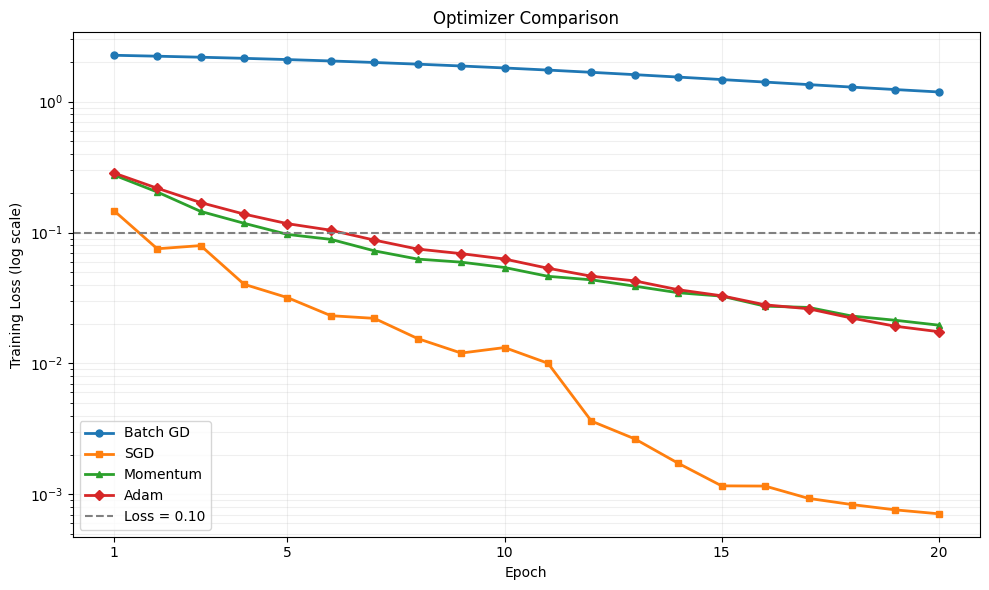

In [23]:
epochs = range(1, EPOCHS + 1)
markers = ["o", "s", "^", "D"]

plt.figure(figsize=(10, 6))

for (name, history), marker in zip(optimizer_results.items(), markers):
    plt.plot(epochs, history["train_loss"], label=name, marker=marker, markersize=5, linewidth=2)

plt.yscale("log")
plt.axhline(0.10, color="gray", linestyle="--", label="Loss = 0.10")

plt.xticks([1, 5, 10, 15, 20])
plt.xlabel("Epoch")
plt.ylabel("Training Loss (log scale)")
plt.title("Optimizer Comparison")
plt.legend()
plt.grid(True, which="both", alpha=0.2)
plt.tight_layout()
plt.show()

In [24]:
for name, history in optimizer_results.items():
    reached = [
        epoch
        for epoch, loss in enumerate(history["train_loss"], start=1)
        if loss <= 0.10
    ]

    if reached:
        print(f"{name}: reached loss <= 0.10 at epoch {reached[0]}")
    else:
        print(f"{name}: did not reach loss <= 0.10 within {EPOCHS} epochs")

Batch GD: did not reach loss <= 0.10 within 20 epochs
SGD: reached loss <= 0.10 at epoch 2
Momentum: reached loss <= 0.10 at epoch 5
Adam: reached loss <= 0.10 at epoch 7


## Comparison of Regularization Methods

In [25]:
regularization_results = {"None": optimizer_results["Adam"]}

for name in ["L2", "L1", "Dropout"]:
    regularization_results[name] = train_model( optimizer_name="Adam", regularization=name, activation="ReLU")

Adam | L2 | ReLU | Epoch 1/20 | Train loss: 0.2877 | Val loss: 0.3045 | Train acc: 91.92% | Val acc: 91.39%
Adam | L2 | ReLU | Epoch 2/20 | Train loss: 0.2218 | Val loss: 0.2432 | Train acc: 93.59% | Val acc: 92.73%
Adam | L2 | ReLU | Epoch 3/20 | Train loss: 0.1724 | Val loss: 0.1989 | Train acc: 95.29% | Val acc: 94.43%
Adam | L2 | ReLU | Epoch 4/20 | Train loss: 0.1420 | Val loss: 0.1742 | Train acc: 96.03% | Val acc: 94.92%
Adam | L2 | ReLU | Epoch 5/20 | Train loss: 0.1201 | Val loss: 0.1541 | Train acc: 96.75% | Val acc: 95.43%
Adam | L2 | ReLU | Epoch 6/20 | Train loss: 0.1085 | Val loss: 0.1462 | Train acc: 97.01% | Val acc: 95.69%
Adam | L2 | ReLU | Epoch 7/20 | Train loss: 0.0912 | Val loss: 0.1309 | Train acc: 97.48% | Val acc: 96.08%
Adam | L2 | ReLU | Epoch 8/20 | Train loss: 0.0790 | Val loss: 0.1210 | Train acc: 97.89% | Val acc: 96.34%
Adam | L2 | ReLU | Epoch 9/20 | Train loss: 0.0731 | Val loss: 0.1161 | Train acc: 97.92% | Val acc: 96.44%
Adam | L2 | ReLU | Epoch 10/

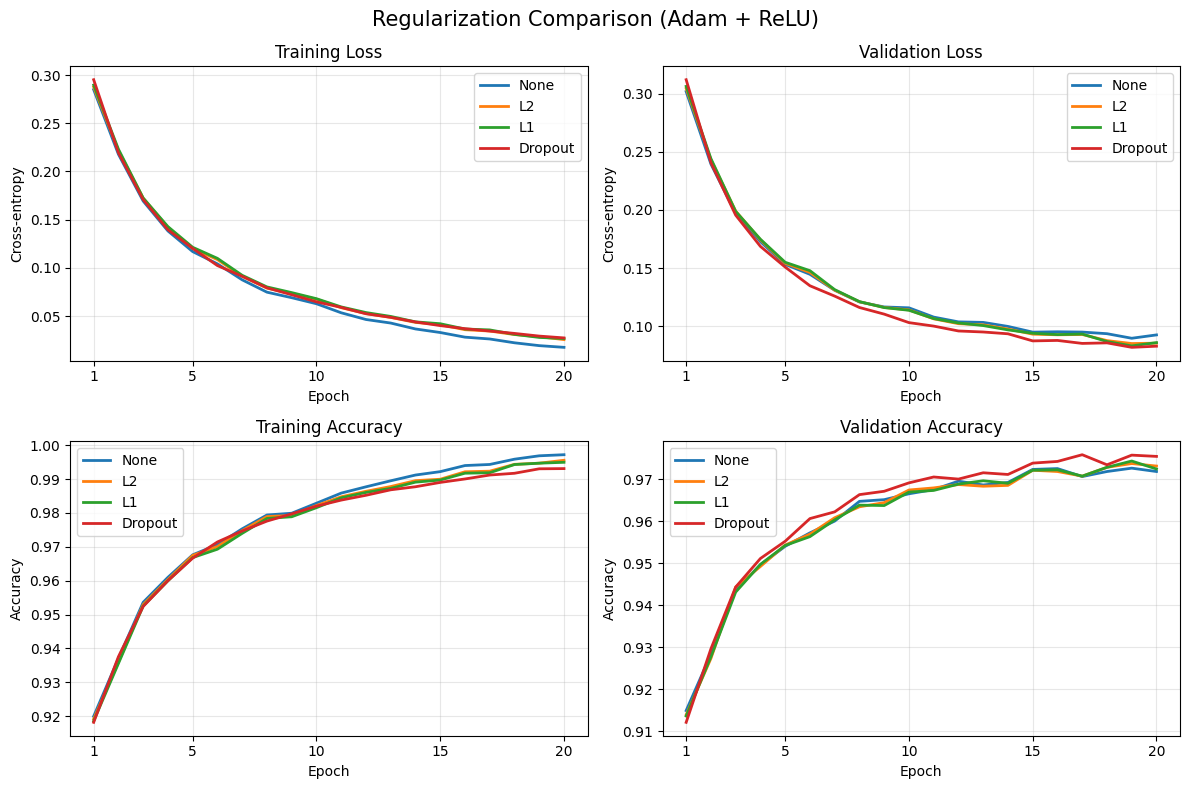

In [27]:
def plot_comparison(results, title):
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))

    metrics = ["train_loss", "val_loss", "train_acc", "val_acc"]
    titles = ["Training Loss", "Validation Loss", "Training Accuracy", "Validation Accuracy"]

    for ax, metric, panel_title in zip(axes.flat, metrics, titles):
        for name, history in results.items():
            ax.plot(range(1, EPOCHS + 1), history[metric], label=name, linewidth=2)
        ax.set_title(panel_title)
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Accuracy" if "acc" in metric else "Cross-entropy")
        ax.set_xticks([1, 5, 10, 15, 20])
        ax.grid(alpha=0.3)
        ax.legend()

    fig.suptitle(title, fontsize=15)
    plt.tight_layout()
    plt.show()

plot_comparison(
    regularization_results,
    "Regularization Comparison (Adam + ReLU)")

In [ ]:
for name, history in regularization_results.items():
    print(f"{name:8s} | "
        f"Weight L2 norm: {history['weight_norm']:.2f} | "
        f"Near-zero weights: {history['near_zero_pct']:.2f}%")

None     | Weight L2 norm: 37.18 | Near-zero weights: 1.00%
L2       | Weight L2 norm: 22.06 | Near-zero weights: 21.12%
L1       | Weight L2 norm: 22.89 | Near-zero weights: 40.75%
Dropout  | Weight L2 norm: 36.57 | Near-zero weights: 1.01%


## Comparison of activation functions
(fixed Adam optimizer, no regularization, identical network architecture; only the activation function is varied)

In [ ]:
# Reuse the existing ReLU baseline
activation_results = {"ReLU": optimizer_results["Adam"]}

for name in ["Sigmoid", "Tanh"]:
    activation_results[name] = train_model(optimizer_name="Adam",regularization="None", activation=name)

Adam | None | Sigmoid | Epoch 1/20 | Train loss: 0.4623 | Val loss: 0.4713 | Train acc: 88.87% | Val acc: 88.50%
Adam | None | Sigmoid | Epoch 2/20 | Train loss: 0.3144 | Val loss: 0.3293 | Train acc: 91.34% | Val acc: 90.80%
Adam | None | Sigmoid | Epoch 3/20 | Train loss: 0.2610 | Val loss: 0.2789 | Train acc: 92.76% | Val acc: 91.91%
Adam | None | Sigmoid | Epoch 4/20 | Train loss: 0.2279 | Val loss: 0.2507 | Train acc: 93.64% | Val acc: 92.63%
Adam | None | Sigmoid | Epoch 5/20 | Train loss: 0.2032 | Val loss: 0.2280 | Train acc: 94.34% | Val acc: 93.35%
Adam | None | Sigmoid | Epoch 6/20 | Train loss: 0.1838 | Val loss: 0.2113 | Train acc: 94.87% | Val acc: 93.71%
Adam | None | Sigmoid | Epoch 7/20 | Train loss: 0.1667 | Val loss: 0.1961 | Train acc: 95.37% | Val acc: 94.26%
Adam | None | Sigmoid | Epoch 8/20 | Train loss: 0.1519 | Val loss: 0.1839 | Train acc: 95.76% | Val acc: 94.54%
Adam | None | Sigmoid | Epoch 9/20 | Train loss: 0.1409 | Val loss: 0.1740 | Train acc: 96.10% |

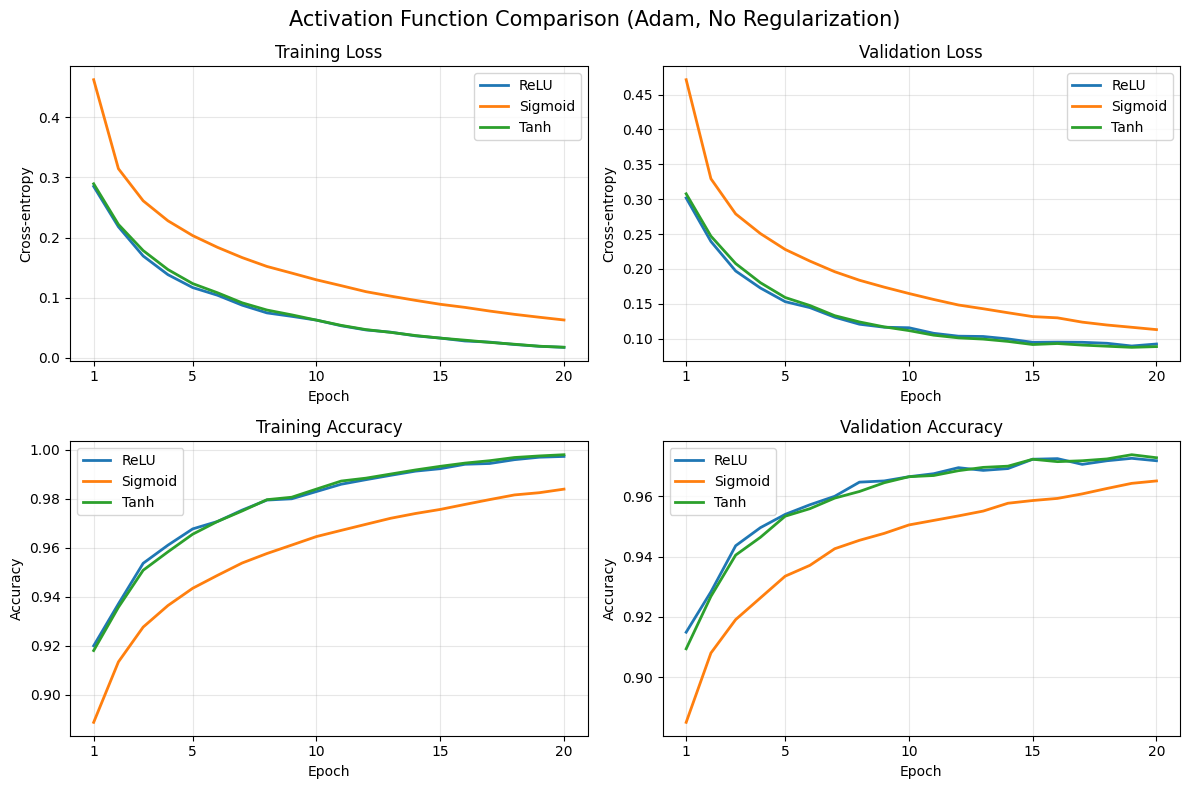

In [30]:
plot_comparison( activation_results, "Activation Function Comparison (Adam, No Regularization)")

In [32]:
for name, history in activation_results.items():
    print(f"{name:8s} | "
        f"Train loss: {history['train_loss'][-1]:.4f} | " f"Val loss: {history['val_loss'][-1]:.4f} | "
        f"Train acc: {history['train_acc'][-1]:.2%} | " f"Val acc: {history['val_acc'][-1]:.2%}")

ReLU     | Train loss: 0.0175 | Val loss: 0.0925 | Train acc: 99.72% | Val acc: 97.18%
Sigmoid  | Train loss: 0.0630 | Val loss: 0.1131 | Train acc: 98.38% | Val acc: 96.51%
Tanh     | Train loss: 0.0177 | Val loss: 0.0888 | Train acc: 99.79% | Val acc: 97.28%


## Collect all configurations without duplicating the Adam baseline

In [ ]:
all_results = {**optimizer_results,
    "Adam + L2": regularization_results["L2"],
    "Adam + L1": regularization_results["L1"],
    "Adam + Dropout": regularization_results["Dropout"],
    "Adam + Sigmoid": activation_results["Sigmoid"],
    "Adam + Tanh": activation_results["Tanh"]}

print(f"{'Configuration':<20} {'Train loss':>11} {'Val loss':>10} " f"{'Train acc':>11} {'Val acc':>10}")

for name, h in all_results.items():
    print(
        f"{name:<20} "
        f"{h['train_loss'][-1]:>11.4f} "
        f"{h['val_loss'][-1]:>10.4f} "
        f"{h['train_acc'][-1]:>11.2%} "
        f"{h['val_acc'][-1]:>10.2%}")

best = max(all_results, key=lambda name: all_results[name]["val_acc"][-1])

print(f"\nHighest final validation accuracy: {best}")

Configuration         Train loss   Val loss   Train acc    Val acc
Batch GD                  1.1849     1.1877      77.70%     78.25%
SGD                       0.0007     0.0893     100.00%     97.93%
Momentum                  0.0196     0.0888      99.66%     97.47%
Adam                      0.0175     0.0925      99.72%     97.18%
Adam + L2                 0.0255     0.0854      99.55%     97.31%
Adam + L1                 0.0266     0.0859      99.49%     97.24%
Adam + Dropout            0.0273     0.0828      99.31%     97.54%
Adam + Sigmoid            0.0630     0.1131      98.38%     96.51%
Adam + Tanh               0.0177     0.0888      99.79%     97.28%

Highest final validation accuracy: SGD
